In [1]:
%env CUDA_DEVICE_ORDER=PCI_BUS_ID
%env CUDA_VISIBLE_DEVICES=0
%pylab inline
%load_ext autoreload
%autoreload 2

env: CUDA_DEVICE_ORDER=PCI_BUS_ID
env: CUDA_VISIBLE_DEVICES=0


ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/gpfs01/berens/user/pgivehchian/ssl_neuron/.venv39/lib64/python3.9/site-packages/traitlets/traitlets.py", line 651, in get
    value = obj._trait_values[self.name]
KeyError: '_control_lock'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/gpfs01/berens/user/pgivehchian/ssl_neuron/.venv39/lib64/python3.9/site-packages/zmq/eventloop/zmqstream.py", line 566, in _log_error
    f.result()
  File "/gpfs01/berens/user/pgivehchian/ssl_neuron/.venv39/lib64/python3.9/site-packages/ipykernel/kernelbase.py", line 301, in dispatch_control
    async with self._control_lock:
  File "/gpfs01/berens/user/pgivehchian/ssl_neuron/.venv39/lib64/python3.9/site-packages/traitlets/traitlets.py", line 706, in __get__
    return self.get(obj, cls)  # type:ignore[return-value]
  File "/gpfs01/berens/user/pgivehchian/ssl_neuron/.venv39/lib64/pyt

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [28]:
import json
import torch
import numpy as np
import pandas as pd
from tqdm import tqdm
import os
from pathlib import Path
from matplotlib.colors import TwoSlopeNorm
import matplotlib.pyplot as plt
import matplotlib as mpl
from openTSNE import TSNE
import colorcet as cc
from sklearn.metrics import confusion_matrix


In [ ]:
from ssl_neuron.datasets import GraphDataset
from ssl_neuron.utils import plot_neuron, knn_accuracy, save_trial_results, knn_predictions_by_celltype
from ssl_neuron.graphdino import create_model

In [47]:
TRIAL = "trial12"

#### Load config

In [63]:
config = json.load(open(f'../configs/{TRIAL}.json'))

In [49]:
# Plotting for later maybe
# dset = GraphDataset(config, mode='all')
# feat, neigh, cell_id = dset.__getsingleitem__(0)
# plot_neuron(neigh, feat)

In [50]:
# plt.scatter(np.arange(config['model']['dim']), cell_meta['latents'].mean(axis=0))

# plt.errorbar(np.arange(config['model']['dim']), cell_meta['latents'].mean(axis=0), yerr = cell_meta['latents'].std(axis=0), fmt='none')

In [51]:
cell_meta = pd.read_csv(os.path.join(config['trainer']['latents_dir'], f'{TRIAL}.csv'))

In [52]:
# Load IDs
data_dir = config['data']['path']

train_ids = np.load(os.path.join(data_dir, 'train_ids.npy')).astype(str)
val_ids = np.load(os.path.join(data_dir, 'val_ids.npy')).astype(str)
test_ids = np.load(os.path.join(data_dir, 'test_ids.npy')).astype(str)

# Create mapping
split_map = {
    **dict.fromkeys(train_ids, 'train'),
    **dict.fromkeys(val_ids, 'val'),
    **dict.fromkeys(test_ids, 'test')
}

# Assign split to each cell
cell_meta['split'] = cell_meta['cell_id'].astype(str).map(split_map)

# Check results
print(cell_meta['split'].value_counts(dropna=False))

NaN      1875
train    1369
val       293
test      293
Name: split, dtype: int64


In [53]:
cell_meta["latent"] = cell_meta["latent"].apply(
    lambda x: np.fromstring(x.strip("[]"), sep=" ")
    if isinstance(x, str) and x.strip()
    else np.array([])
)

In [54]:
def get_celltype_colors(cell_meta):
    celltypes = sorted(cell_meta['celltype_final'].dropna().unique())

    colors = cc.glasbey[:len(celltypes)]

    color_dict = dict(zip(celltypes, colors))

    return color_dict

color_dict = get_celltype_colors(cell_meta)

In [55]:
def plot_tsne(
    cell_meta,
    unknown_labels=True,
    color_by='celltype',
    perplexity=30,
    random=True,
    color_dict=None
):

    if unknown_labels:
        plot_df = cell_meta.copy()
    else:
        plot_df = cell_meta[cell_meta['celltype_final'].notna()].copy()

    X = np.stack(plot_df['latent'].values).astype(np.float32)

    print("Embedding shape:", X.shape)
    print("Embedding dtype:", X.dtype)

    # Run t-SNE
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=42,
        initialization='pca',
        learning_rate=200.0,
        n_jobs=-1
    )

    X_tsne = np.array(tsne.fit(X))

    plot_df['TSNE1'] = X_tsne[:, 0]
    plot_df['TSNE2'] = X_tsne[:, 1]

    if random:
        plot_df = plot_df.sample(frac=1).reset_index(drop=True)

    fig, ax = plt.subplots(
        figsize=(8, 5) if color_by != 'celltype' else (12, 5)
    )

    # 1. Color by cell type
    if color_by == 'celltype':

        if color_dict is None:
            color_dict = get_celltype_colors(plot_df)

        point_colors = plot_df['celltype_final'].map(color_dict)

        if unknown_labels:
            point_colors = point_colors.fillna('lightgrey')

        ax.scatter(
            plot_df['TSNE1'],
            plot_df['TSNE2'],
            c=point_colors,
            s=15,
            alpha=0.8,
            zorder=2
        )

        from matplotlib.lines import Line2D

        legend_elements = [
            Line2D(
                [0], [0],
                marker='o',
                color='w',
                label=str(celltype),
                markerfacecolor=color,
                markersize=6
            )
            for celltype, color in color_dict.items()
        ]

        if unknown_labels:
            legend_elements.append(
                Line2D(
                    [0], [0],
                    marker='o',
                    color='w',
                    label='Unknown',
                    markerfacecolor='lightgrey',
                    markersize=6
                )
            )

        ax.legend(
            handles=legend_elements,
            title='Cell Type',
            bbox_to_anchor=(1.02, 1),
            loc='upper left',
            ncol=2,
            fontsize=8,
            markerscale=1.5
        )

    # 2. Color by a continuous variable
    elif color_by in plot_df.columns and color_by != 'none':

        values = plot_df[color_by].to_numpy(dtype=float)

        vmin, vmax = np.nanpercentile(values, [2, 98])
        vcenter = np.nanmean(values)

        norm = TwoSlopeNorm(
            vmin=vmin,
            vcenter=vcenter,
            vmax=vmax
        )

        cmap = mpl.colormaps['RdBu_r']

        if random:
            order = np.random.permutation(len(plot_df))
        else:
            order = np.arange(len(plot_df))

        sc = ax.scatter(
            plot_df['TSNE1'].to_numpy()[order],
            plot_df['TSNE2'].to_numpy()[order],
            c=values[order],
            cmap=cmap,
            norm=norm,
            s=15,
            alpha=0.8
        )

        cbar = fig.colorbar(sc, ax=ax)
        cbar.set_label(color_by)

    # 3. Single color
    elif color_by == 'none':

        ax.scatter(
            plot_df['TSNE1'],
            plot_df['TSNE2'],
            color='steelblue',
            s=15,
            alpha=0.7
        )

    else:
        raise ValueError(
            f"Unknown color_by='{color_by}'. "
            "Use 'celltype', 'none', or a numerical column name."
        )

    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')
    ax.set_title(f't-SNE of Neuron Embeddings (colored by {color_by})')

    plt.tight_layout()
    plt.show()

    return plot_df

Embedding shape: (1662, 32)
Embedding dtype: float32


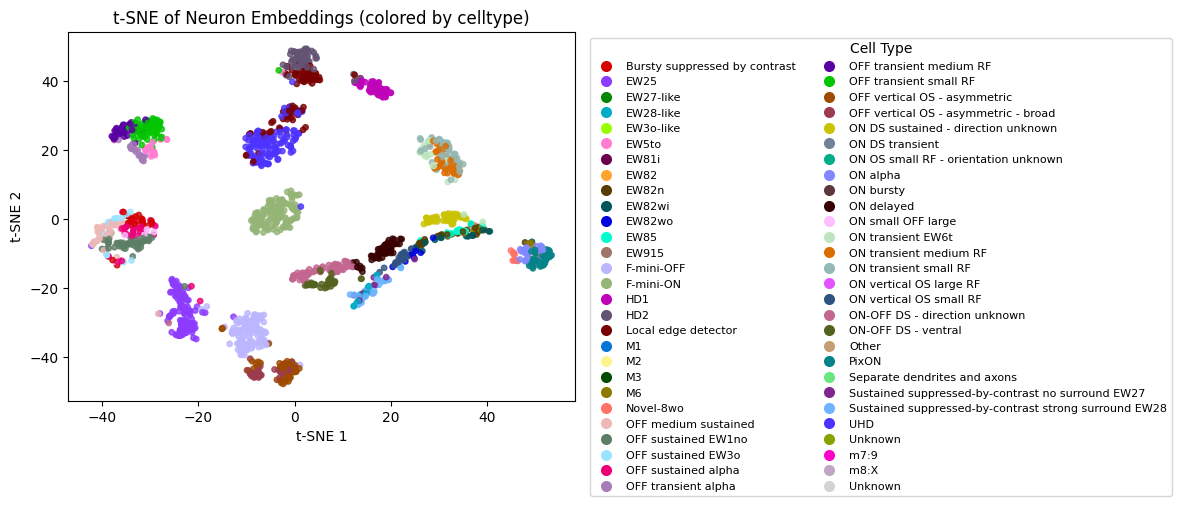

Embedding shape: (1662, 32)
Embedding dtype: float32


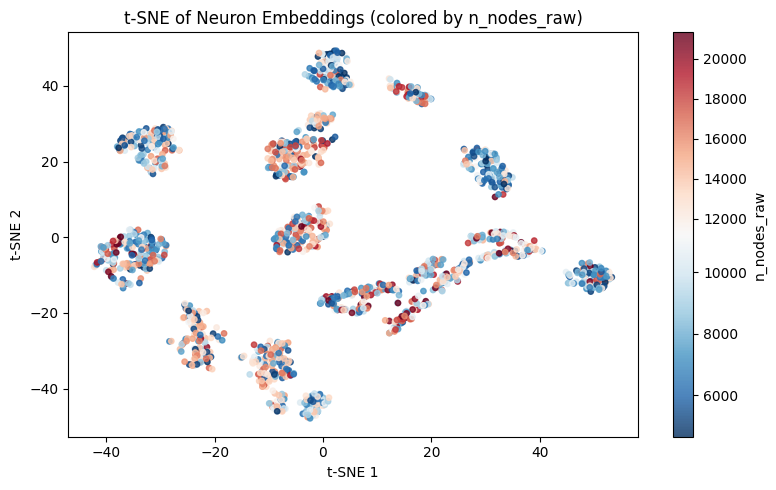

In [56]:
# plot_df = plot_tsne(cell_meta, unknown_labels=False, color_by='celltype')

plot_df = plot_tsne(cell_meta[cell_meta['split'].isin(['train', 'val'])], unknown_labels=True, color_dict=color_dict, color_by='celltype')

plot_df = plot_tsne(cell_meta[cell_meta['split'].isin(['train', 'val'])], color_by='n_nodes_raw')
# plot_df = plot_tsne(cell_meta[cell_meta['split'].isin(['train', 'val'])], color_by='z_mean')

# plot_df = plot_tsne(cell_meta[cell_meta['split'] == 'train'], color_dict=color_dict, color_by='soma_z')


Training losses:
[6.58300734 7.05073833 6.94082546 6.77872849 6.5796361  6.27447748
 5.78297949 5.19339848 4.60076141 4.09610653 3.65999913 3.29217935
 2.99012566 2.66702604 2.44226432 2.20289302 1.99663973 1.84944963
 1.60605145 1.47968543 1.29795933 1.19840157 1.11526477 1.03198326
 0.95879465 0.89812559 0.82470578 0.81264937 0.78069174 0.78618658
 0.74904668 0.7645849  0.7797032  0.75733852 0.73914075 0.77229434
 0.73892558 0.76327282 0.74329245 0.74086094 0.7148931  0.69738603
 0.74122763 0.71494287 0.7167995  0.69564849 0.71232313 0.6644038
 0.69585598 0.67137462 0.64456916 0.69519061 0.64217228 0.65321946
 0.63688523 0.60919243 0.65260971 0.6293022  0.6146543  0.59340584
 0.60121983 0.58140647 0.55500019 0.57598287 0.58444911 0.5563249
 0.5672614  0.52949834 0.52872318 0.54746819 0.54339451 0.52697778
 0.50182408 0.52916574 0.50697178 0.48876771 0.49710852 0.47674477
 0.50197202 0.48473835 0.48619807 0.47403815 0.46541604 0.47237509
 0.4719342  0.46277297 0.48205167 0.46117926 0.

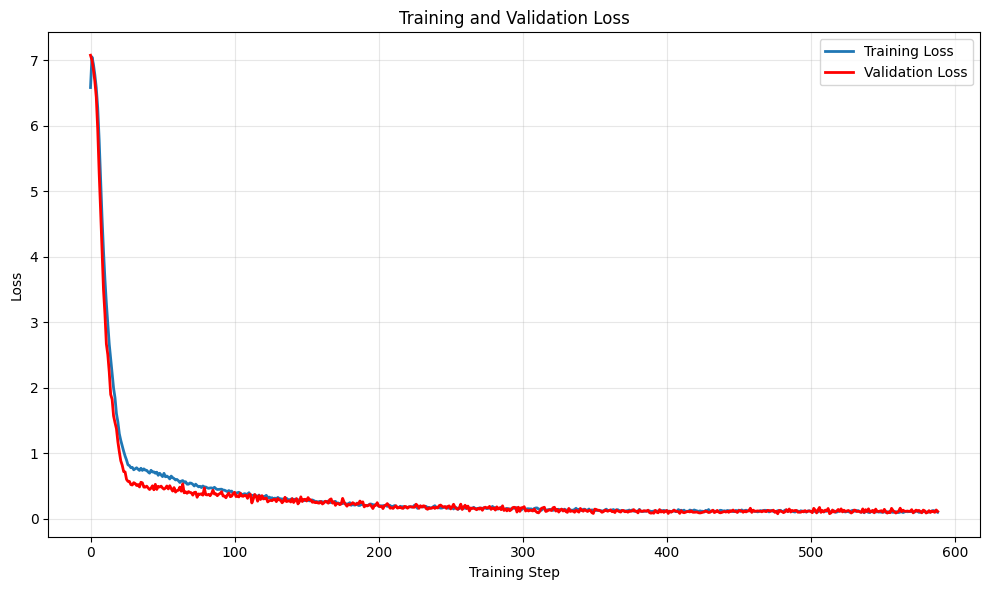

In [57]:
loss_dir = Path("..") / Path(config['trainer']['losses_dir']) / Path(TRIAL)

losses = np.load(loss_dir / "training_loss.npy")
val_losses = np.load(loss_dir / "val_loss.npy")

print("Training losses:")
print(losses)

print("\nValidation losses:")
print(val_losses)

print(f"\nNumber of training steps: {len(losses)}")
print(f"Initial training loss: {losses[0]:.6f}")
print(f"Final training loss: {losses[-1]:.6f}")
print(f"Minimum training loss: {np.min(losses):.6f}")

print(f"\nNumber of validation steps: {len(val_losses)}")
print(f"Initial validation loss: {val_losses[0]:.6f}")
print(f"Final validation loss: {val_losses[-1]:.6f}")
print(f"Minimum validation loss: {np.min(val_losses):.6f}")

plt.figure(figsize=(10, 6))

plt.plot(losses, label="Training Loss", linewidth=2)
plt.plot(val_losses, label="Validation Loss", color="red", linewidth=2)

plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## KNN accuracy

In [59]:
accuracy, results = knn_accuracy(
    cell_meta[
        (cell_meta["split"].isin(["train", "val"]))
    ],
    cell_meta[
        (cell_meta["split"].isin(["val"]))
    ],
    k = 5,
    balanced=True, 
    print_val=True
)

Cells in whole space: 1662
Cells evaluated: 293
Cell types: All
k: 5
Balanced KNN accuracy: 0.6978 (69.78%)


## KNN confusion matrices by cell type

The rows are the true cell types and the columns are the predicted cell types. Train and validation predictions are evaluated separately.

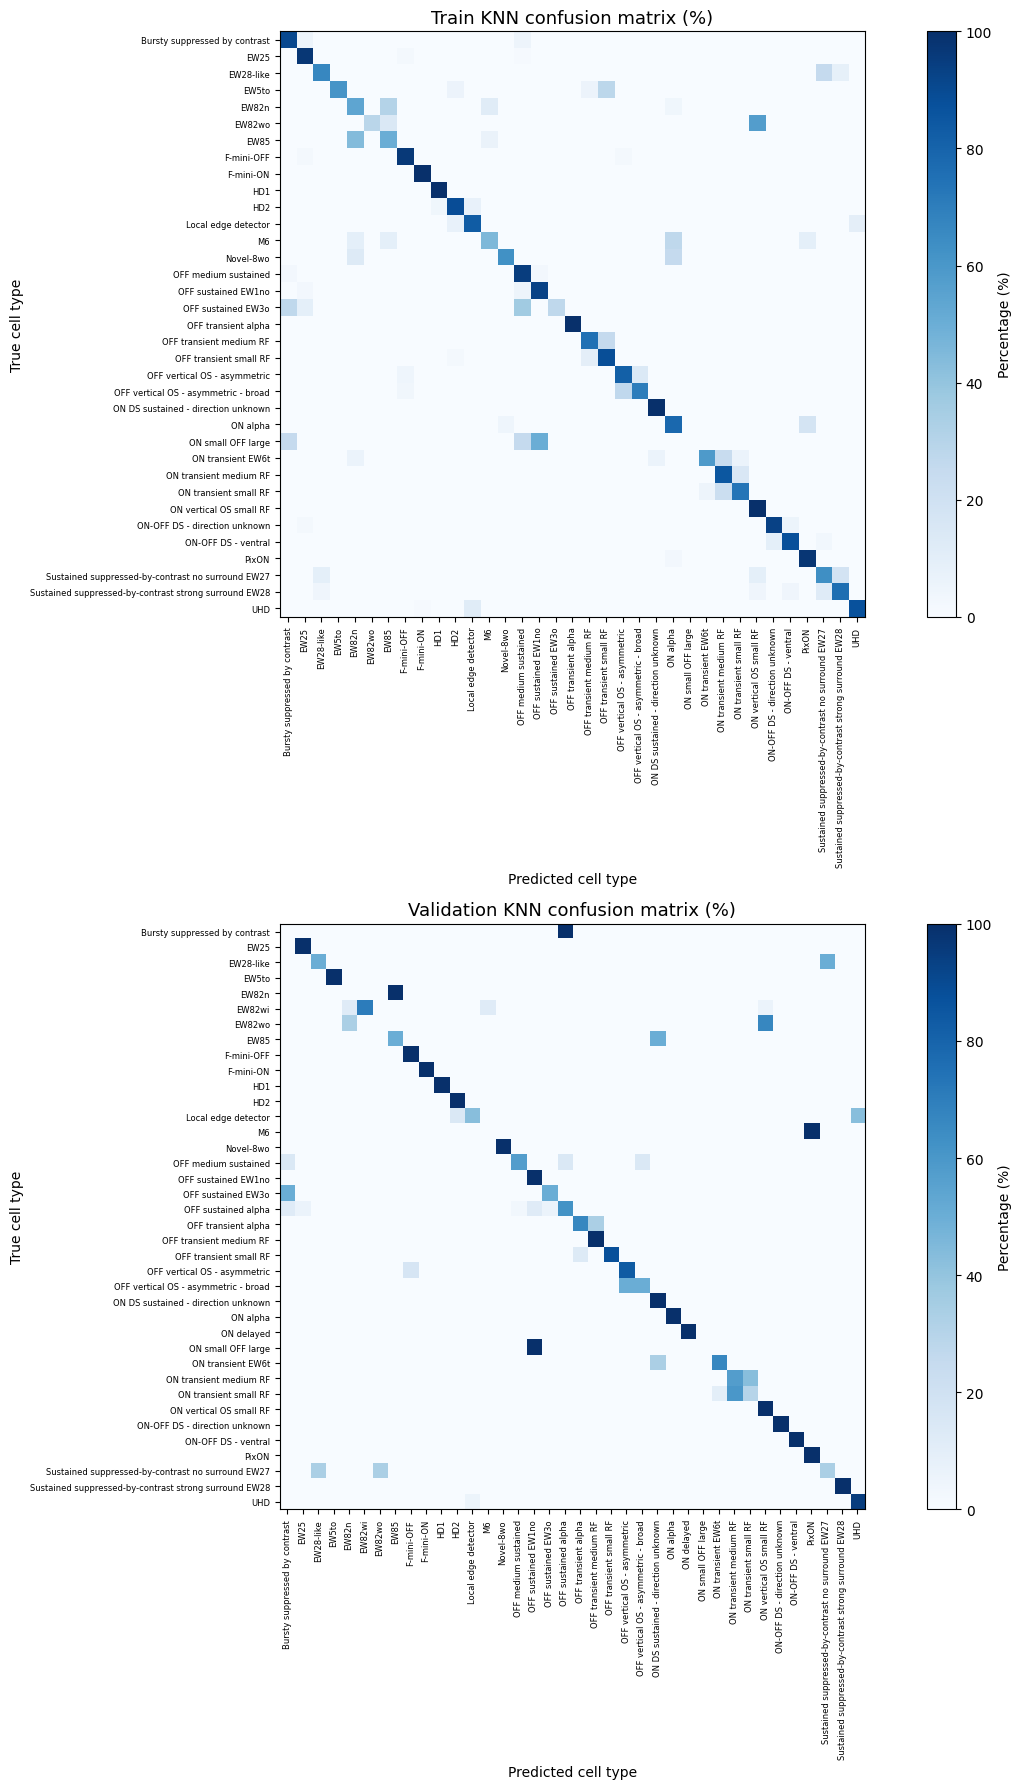

In [ ]:
train_cells = cell_meta[cell_meta["split"] == "train"]
val_cells = cell_meta[cell_meta["split"] == "val"]
train_val_cells = cell_meta[cell_meta["split"].isin(["val", "train"])]

train_cell_types = sorted(
    set(train_cells["celltype_final"].dropna().unique())
)
val_cell_types = sorted(
    set(val_cells["celltype_final"].dropna().unique())
)


train_knn_results, train_type_accuracy = knn_predictions_by_celltype(train_cells, train_cells, train_cell_types, k=5)
val_knn_results, val_type_accuracy = knn_predictions_by_celltype(train_val_cells, val_cells, val_cell_types, k=5)


# Calculate confusion matrices
train_cm = confusion_matrix(
    train_knn_results["celltype_final"],
    train_knn_results["predicted_celltype"],
    labels=train_cell_types
)

val_cm = confusion_matrix(
    val_knn_results["celltype_final"],
    val_knn_results["predicted_celltype"],
    labels=val_cell_types
)

# Normalize each row to percentages
train_cm_norm = train_cm.astype(float) / train_cm.sum(axis=1, keepdims=True) * 100
val_cm_norm = val_cm.astype(float) / val_cm.sum(axis=1, keepdims=True) * 100

# Handle cell types with no evaluation samples
train_cm_norm = np.nan_to_num(train_cm_norm)
val_cm_norm = np.nan_to_num(val_cm_norm)

fig, axes = plt.subplots(2, 1, figsize=(16, 18))

for ax, matrix, labels, title in zip(
    axes,
    [train_cm_norm, val_cm_norm],
    [train_cell_types, val_cell_types],
    ["Train KNN confusion matrix (%)", "Validation KNN confusion matrix (%)"]
):
    image = ax.imshow(
        matrix,
        interpolation="nearest",
        cmap="Blues",
        vmin=0,
        vmax=100
    )

    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Predicted cell type", fontsize=10)
    ax.set_ylabel("True cell type", fontsize=10)

    ax.set_xticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=90, fontsize=6)

    ax.set_yticks(np.arange(len(labels)))
    ax.set_yticklabels(labels, fontsize=6)

    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="Percentage (%)")

plt.tight_layout()
plt.show()

In [45]:
type_accuracy = train_type_accuracy.rename(columns={"accuracy": "train_accuracy"}).merge(
    val_type_accuracy.rename(columns={"accuracy": "val_accuracy"}), on="celltype", how="outer"
)
type_accuracy


,celltype,train_accuracy,val_accuracy
0,Bursty suppressed by contrast,0.857143,0.000000
1,EW25,0.960784,1.000000
2,EW28-like,0.833333,1.000000
3,EW5to,0.388889,1.000000
4,EW82n,0.692308,0.000000
5,EW82wo,0.428571,0.333333
6,EW85,0.375000,1.000000
7,F-mini-OFF,0.981308,1.000000
8,F-mini-ON,1.000000,1.000000
9,HD1,0.886792,1.000000


## Save results

In [15]:
trial_results = save_trial_results(
    cell_meta[
            (cell_meta["split"].isin(["train", "val"]))
        ],
    config=config,
    TRIAL=TRIAL,
    k=5
)


Results saved to /gpfs01/berens/user/pgivehchian/ssl_neuron/outputs/results.csv


In [16]:
trial_results

,trial,train_acc,val_acc,balanced_train_acc,balanced_val_acc,k,confidence,max_iter,lr,exp_decay,...,jitter_var,translate_var,rotation_axis,n_drop_branch,dim,depth,n_head,pos_dim,move_avg,teacher_temp
0,trial14,0.831994,0.795222,0.735771,0.651647,5,None,35000,0.0001,0.5,...,"[1, 1, 0.2]","[10, 10, 0]",z,10,32,7,8,32,0.999,0.06


In [17]:
results = pd.read_csv('/gpfs01/berens/user/pgivehchian/ssl_neuron/outputs/results.csv')

In [18]:
results

,trial,train_acc,val_acc,balanced_train_acc,balanced_val_acc,k,confidence,max_iter,lr,exp_decay,...,jitter_var,translate_var,rotation_axis,n_drop_branch,dim,depth,n_head,pos_dim,move_avg,teacher_temp
0,trial9,0.794433,0.771993,NaN,NaN,5.0,High,20000.0,0.0001,0.5,...,"[1, 1, 0.2]","[5, 5, 0]",z,10,32,7,8,32.0,0.999,0.06
1,trial10,0.609208,0.520646,NaN,NaN,5.0,High,20000.0,0.0001,0.5,...,"[1, 1, 0.2]","[5, 5, 0]",z,10,32,7,8,32.0,0.999,0.06
2,trial12,0.851717,0.805461,0.709643,0.639680,10.0,NaN,50000.0,0.0001,0.5,...,"[1, 1, 0.2]","[5, 5, 0]",z,10,32,7,8,32.0,0.999,0.06
3,trial12,0.861943,0.812287,0.758209,0.649837,5.0,NaN,50000.0,0.0001,0.5,...,"[1, 1, 0.2]","[5, 5, 0]",z,10,32,7,8,32.0,0.999,0.06
4,trial13,0.832725,0.767918,0.731023,0.601553,5.0,NaN,30000.0,0.0001,0.5,...,"[1, 1, 0.2]","[5, 5, 0]",z,10,32,7,8,32.0,0.999,0.06
5,trial14,0.831994,0.795222,0.735771,0.651647,5.0,NaN,35000.0,0.0001,0.5,...,"[1, 1, 0.2]","[10, 10, 0]",z,10,32,7,8,32.0,0.999,0.06


## KNN Accuracy over training

In [ ]:
acc_dir = Path("..") / Path(config['trainer']['acc_dir']) / f"{TRIAL}.csv"

accuracies = pd.read_csv(acc_dir)

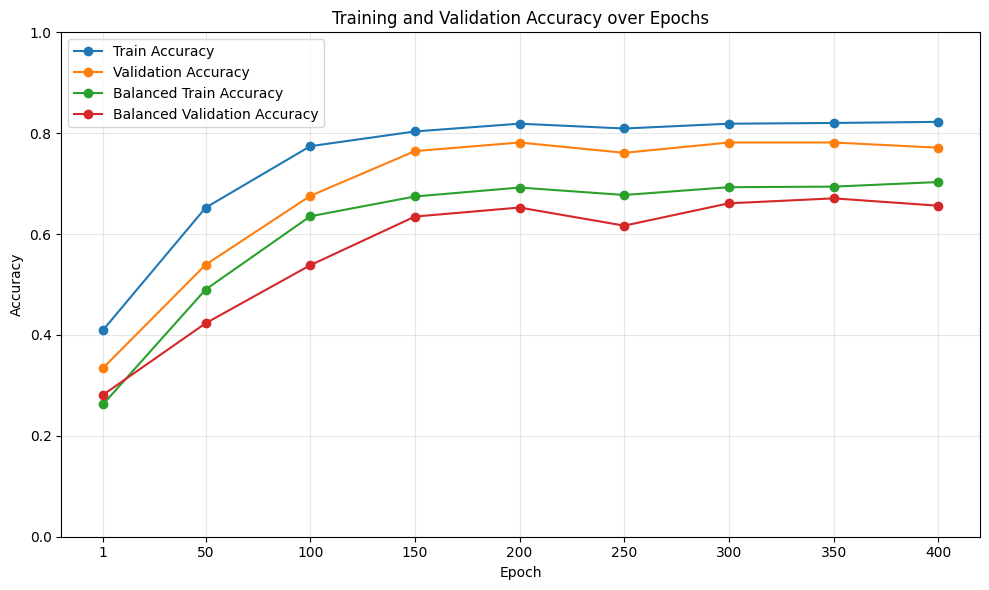

In [21]:
plt.figure(figsize=(10, 6))

plt.plot(accuracies["epoch"], accuracies["train_acc"],
         marker="o", label="Train Accuracy")

plt.plot(accuracies["epoch"], accuracies["val_acc"],
         marker="o", label="Validation Accuracy")

plt.plot(accuracies["epoch"], accuracies["balanced_train_acc"],
         marker="o", label="Balanced Train Accuracy")

plt.plot(accuracies["epoch"], accuracies["balanced_val_acc"],
         marker="o", label="Balanced Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy over Epochs")

plt.xticks(accuracies["epoch"])
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Data Analysis

### z means

In [22]:
z_means = []

for _, row in tqdm(cell_meta.iterrows(), total=len(cell_meta)):

    cell_id = int(row['cell_id'])

    feature_path = os.path.join(
        config['data']['path'],
        'skeletons',
        str(cell_id),
        'features.npy'
    )

    if os.path.exists(feature_path):

        features = np.load(feature_path)
        z_values = features[:, 2]
        z_mean = np.nanmean(z_values)

    else:
        print(f"Missing features: {cell_id}")
        z_mean = np.nan

    z_means.append(z_mean)

cell_meta['z_mean'] = z_means

  0%|          | 0/3830 [00:00<?, ?it/s]

100%|██████████| 3830/3830 [01:40<00:00, 37.95it/s]


Embedding shape: (1662, 32)
Embedding dtype: float32


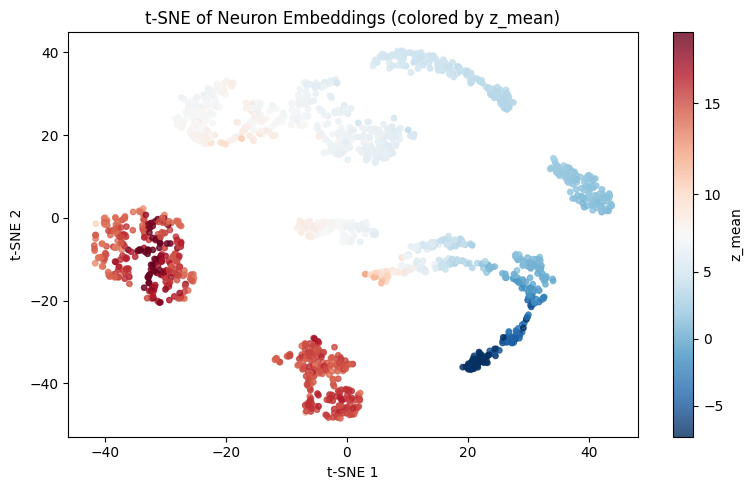

In [23]:
plot_df = plot_tsne(cell_meta[cell_meta['split'].isin(['train', 'val'])], unknown_labels=True, color_by='z_mean')